In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

print("Shape of train data:", df.shape)
print("Shape of test data:", test_df.shape)
print(df.head())
df.info()
print(df.describe())

target = 'SalePrice'
num_features = ['GrLivArea', 'OverallQual', 'TotalBsmtSF', 'GarageCars', 'YearBuilt', 'FullBath', 'LotArea']
cat_features = ['Neighborhood', 'HouseStyle', 'KitchenQual', 'CentralAir']

print("Dependent variable:", target)
print("Numerical features:", num_features)
print("Categorical features:", cat_features)

# SalePrice is a continuous number (not a class label), so this is a regression problem.
# So we use MAE/MSE/RMSE/R2 instead of accuracy or confusion matrix.

Shape of train data: (1460, 81)
Shape of test data: (1459, 80)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrS

In [3]:
from sklearn.model_selection import train_test_split

data = df[num_features + cat_features + [target]].copy()
print(data.isnull().sum())

# fill the missing values (median for numbers)
for col in num_features:
    data[col] = data[col].fillna(data[col].median())

# CentralAir is binary (Y/N) so map to 1/0
data['CentralAir'] = data['CentralAir'].map({'Y': 1, 'N': 0})

# KitchenQual has a natural order so ordinal encoding is used
kitchen_map = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
data['KitchenQual'] = data['KitchenQual'].map(kitchen_map)

# Neighborhood and HouseStyle have no order, so one-hot encoding is used
data = pd.get_dummies(data, columns=['Neighborhood', 'HouseStyle'], drop_first=True, dtype=int)

X = data.drop(target, axis=1)
y = data[target]

print("All numeric?", all(X.dtypes != 'object'))
print("Missing values in X:", X.isnull().sum().sum())
print("X shape:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)

GrLivArea       0
OverallQual     0
TotalBsmtSF     0
GarageCars      0
YearBuilt       0
FullBath        0
LotArea         0
Neighborhood    0
HouseStyle      0
KitchenQual     0
CentralAir      0
SalePrice       0
dtype: int64
All numeric? True
Missing values in X: 0
X shape: (1460, 40)
X_train: (1168, 40) X_test: (292, 40)
y_train: (1168,) y_test: (292,)


In [4]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

comparison = pd.DataFrame({'Actual': y_test.values[:10], 'Predicted': y_pred[:10].round(0)})
comparison['Difference'] = comparison['Actual'] - comparison['Predicted']
print(comparison)

   Actual  Predicted  Difference
0  154500   137634.0     16866.0
1  325000   324487.0       513.0
2  115000   116264.0     -1264.0
3  159000   171335.0    -12335.0
4  315500   285173.0     30327.0
5   75500    67453.0      8047.0
6  311500   239580.0     71920.0
7  146000   145539.0       461.0
8   84500    67267.0     17233.0
9  135500   121460.0     14040.0


In [5]:
print("Intercept:", model.intercept_)

coef_table = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
interpretation = []
for i in range(len(coef_table)):
    f = coef_table['Feature'][i]
    c = coef_table['Coefficient'][i]
    if c >= 0:
        word = "increase"
    else:
        word = "decrease"
    if X[f].nunique() == 2:
        text = "Having " + f + " (vs not) is associated with a price " + word + " of about " + str(round(abs(c))) + ", holding others constant"
    else:
        text = "Each 1 unit increase in " + f + " is associated with a price " + word + " of about " + str(round(abs(c))) + ", holding others constant"
    interpretation.append(text)
coef_table['Interpretation'] = interpretation

pd.set_option('display.max_colwidth', 200)
pd.set_option('display.width', 250)
print(coef_table.to_string())

# The intercept is the predicted price when every feature is 0 (0 area, 0 quality, year 0 ...).
# That is impossible for a real house, so the intercept has no sensible real-world meaning here;
# it only shifts the regression line. (Neighborhood/HouseStyle coefficients are compared to the
# dropped baseline category.)

Intercept: -542966.4311351428
                 Feature   Coefficient                                                                                                    Interpretation
0              GrLivArea     57.396365        Each 1 unit increase in GrLivArea is associated with a price increase of about 57, holding others constant
1            OverallQual  13928.809110   Each 1 unit increase in OverallQual is associated with a price increase of about 13929, holding others constant
2            TotalBsmtSF      4.359893       Each 1 unit increase in TotalBsmtSF is associated with a price increase of about 4, holding others constant
3             GarageCars  10150.836511    Each 1 unit increase in GarageCars is associated with a price increase of about 10151, holding others constant
4              YearBuilt    221.696929       Each 1 unit increase in YearBuilt is associated with a price increase of about 222, holding others constant
5               FullBath  -2500.858758       Each 1 

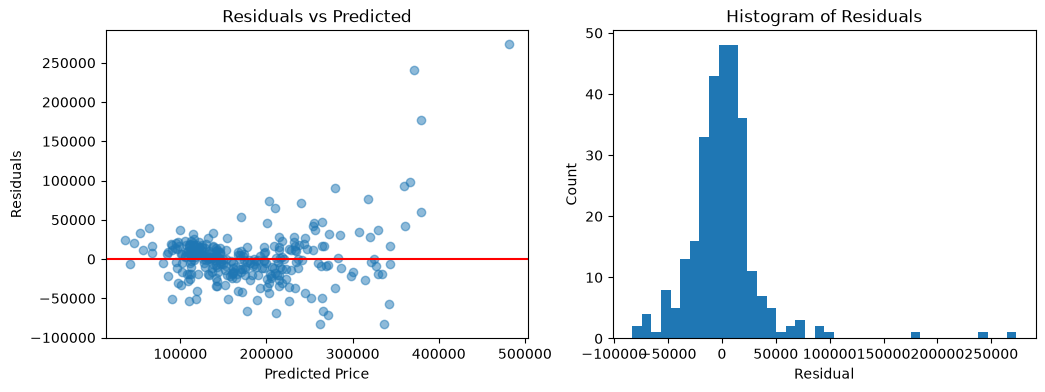

  Metric          Test
0    MAE  2.135647e+04
1    MSE  1.254956e+09
2   RMSE  3.542536e+04
3     R2  8.363881e-01


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

residuals = y_test - y_pred

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red')
plt.xlabel('Predicted Price')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')

plt.subplot(1, 2, 2)
plt.hist(residuals, bins=40)
plt.xlabel('Residual')
plt.ylabel('Count')
plt.title('Histogram of Residuals')
plt.show()
# Residuals are centered around 0 but spread out more for expensive houses (funnel shape),
# and there are a few big outliers, so the errors are not perfectly random.

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

test_metrics = pd.DataFrame({'Metric': ['MAE', 'MSE', 'RMSE', 'R2'], 'Test': [mae, mse, rmse, r2]})
print(test_metrics)

# MAE = average error in dollars. MSE = average squared error (punishes big errors).
# RMSE = typical error in dollars (same unit as price). R2 = share of price variation explained.
# For a non-technical person MAE is best because it is in dollars and easy to understand.

In [7]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_mae = mean_absolute_error(y_train, train_pred)
train_mse = mean_squared_error(y_train, train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, train_pred)

compare_table = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2'],
    'Training': [train_mae, train_mse, train_rmse, train_r2],
    'Testing': [mae, mse, rmse, r2]
})
print(compare_table)

# If train R2 is much higher than test R2 the model is overfitting.
# Here train R2 (~0.82) and test R2 (~0.84) are very close, so there is no overfitting
# and the model generalizes well.

  Metric      Training       Testing
0    MAE  2.064215e+04  2.135647e+04
1    MSE  1.073454e+09  1.254956e+09
2   RMSE  3.276362e+04  3.542536e+04
3     R2  8.200276e-01  8.363881e-01


In [9]:
# (a) Most influential features
# raw coefficients are not comparable because the features have different scales
# (e.g. GrLivArea is in sq ft, OverallQual is 1-10), so we also multiply by the feature std
coef_table['Abs_Coef'] = coef_table['Coefficient'].abs()
print(coef_table.sort_values('Abs_Coef', ascending=False)[['Feature', 'Coefficient']].head(8))

coef_table['Std_Coef'] = model.coef_ * X_train.std().values
print(coef_table.reindex(coef_table['Std_Coef'].abs().sort_values(ascending=False).index)[['Feature', 'Std_Coef']].head(8))
# Raw coefficients make some neighborhoods look biggest, but after scaling
# GrLivArea and OverallQual are the most influential features (then NridgHt/NoRidge neighborhoods).

# (b) Final interpretation (write this in a markdown cell):
# The model explains about 84% of the variation in house prices (test R2), with a typical error of
# about $35k (RMSE) and an average error of about $21k (MAE). MAE/RMSE are the most useful
# because they are in dollars. GrLivArea and OverallQual have the strongest effect.
# Limitations: it assumes straight-line relationships, is sensitive to outliers, the residuals
# spread out for expensive houses, and we used only 11 of 79 features.
# Next: log-transform SalePrice, add more features, try Ridge/Lasso or Random Forest.

# (c) Kaggle submission - apply the same steps to test.csv
sub_df = test_df[num_features + cat_features].copy()
for col in num_features:
    sub_df[col] = sub_df[col].fillna(df[col].median())   # use train median
sub_df['CentralAir'] = sub_df['CentralAir'].map({'Y': 1, 'N': 0})
sub_df['KitchenQual'] = sub_df['KitchenQual'].map(kitchen_map)
sub_df['KitchenQual'] = sub_df['KitchenQual'].fillna(3)   # 1 missing value -> typical (TA)
sub_df = pd.get_dummies(sub_df, columns=['Neighborhood', 'HouseStyle'], drop_first=True, dtype=int)
sub_df = sub_df.reindex(columns=X.columns, fill_value=0)  # same columns as training

final_pred = model.predict(sub_df)
final_pred = np.where(final_pred < 0, df[target].min(), final_pred)  # no negative prices

submission = pd.DataFrame({'Id': test_df['Id'], 'SalePrice': final_pred})
submission.to_csv('submission.csv', index=False)
print(submission.shape)
print(submission.head())

# after submitting on the kaggle my score is: 0.40613 and the over all rank is: 3536 


                 Feature   Coefficient
23  Neighborhood_NoRidge  72377.058297
30  Neighborhood_StoneBr  69989.169222
24  Neighborhood_NridgHt  68190.411662
32  Neighborhood_Veenker  56619.327298
14  Neighborhood_Crawfor  46066.796856
12  Neighborhood_ClearCr  39510.697024
29  Neighborhood_Somerst  31347.448858
11  Neighborhood_BrkSide  29205.121513
                 Feature      Std_Coef
0              GrLivArea  30100.530036
1            OverallQual  19049.307580
24  Neighborhood_NridgHt  15177.672965
23  Neighborhood_NoRidge  11997.727090
7            KitchenQual   9790.445883
30  Neighborhood_StoneBr   9083.640352
14  Neighborhood_Crawfor   8774.869374
3             GarageCars   7513.256875
(1459, 2)
     Id      SalePrice
0  1461  112466.900231
1  1462  168873.676428
2  1463  159500.803276
3  1464  184788.986050
4  1465  258451.299888
